# Quantization and other methods

In [ ]:
# Environment for week12: Quantization (int8 from scratch, torch, bitsandbytes, ONNX static), GPTQ, QLoRA.
# Colab or a fresh virtualenv: run this cell once. Locally: `uv sync --group week12` in the repo root instead.
# GPTQ needs Linux + an NVIDIA GPU: %pip install -q "gptqmodel>=2.0" (the backend transformers uses now; auto-gptq is unmaintained).
%pip install -q "torch>=2.4,<3" "transformers>=4.56,<5" "datasets>=3.6,<4" "evaluate>=0.4.3" "accelerate>=1.0" "peft>=0.13,<1" "tqdm>=4.66" "optimum-onnx[onnxruntime]>=0.1" "onnxruntime>=1.19"

Based on HF quantization blogpost https://huggingface.co/blog/gptq-integration

## Quantization

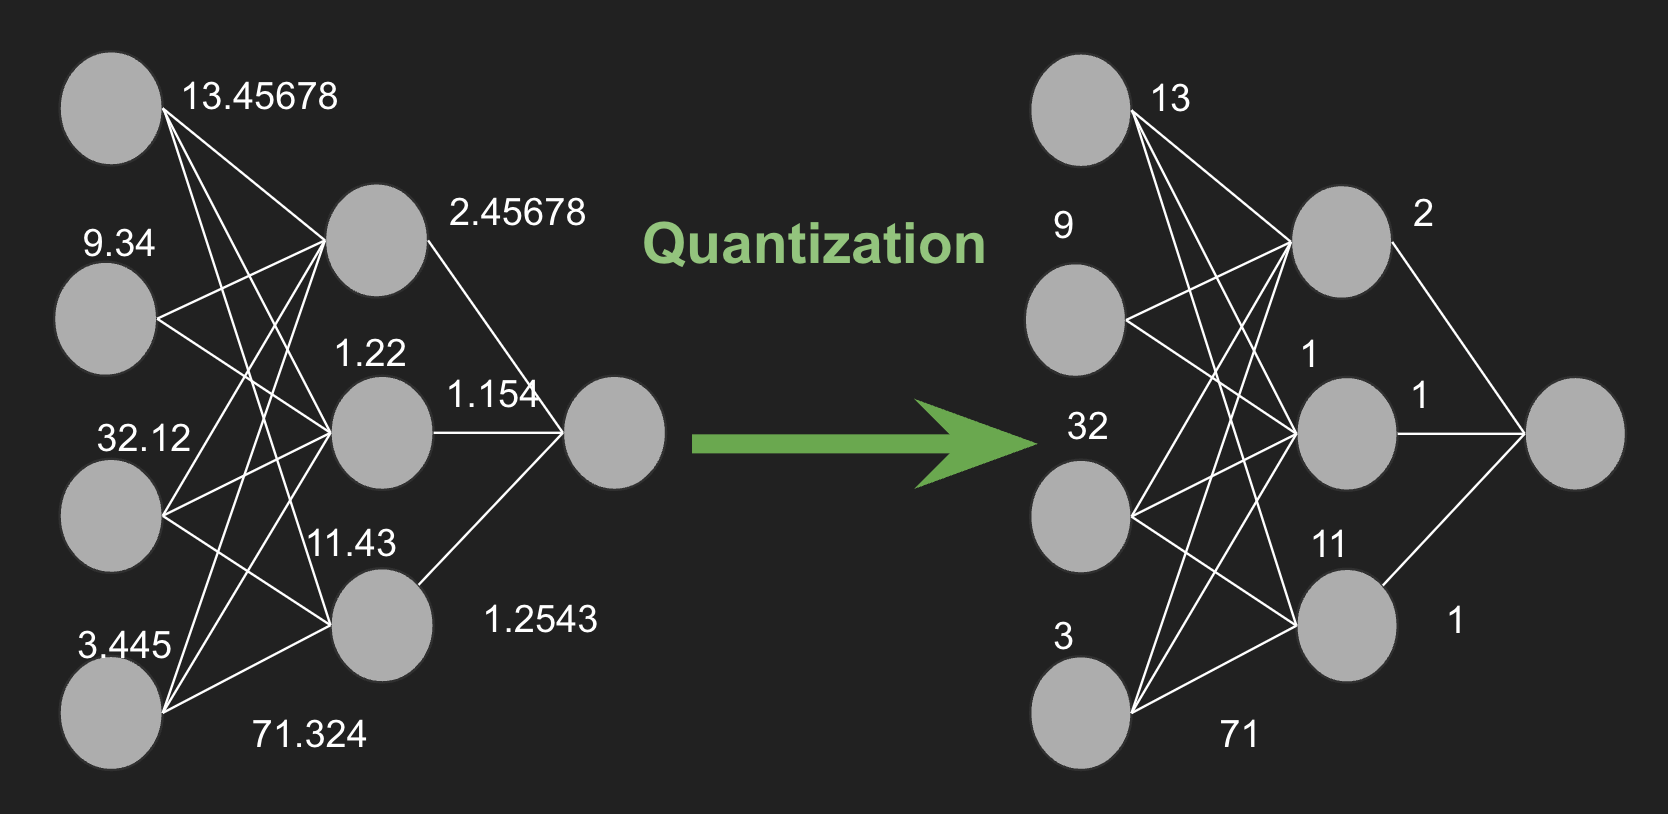

There are a lot of methods for model's speed up and compression:

1.   Quantization
2.   Distillation
3.   Pruning



Quantization quantize model's weights after training or during training. Some methods require additional training data for quantization (calibration dataset), some works without external datasets. Moreover, some methods quantize only activations, or only some choosen weights.

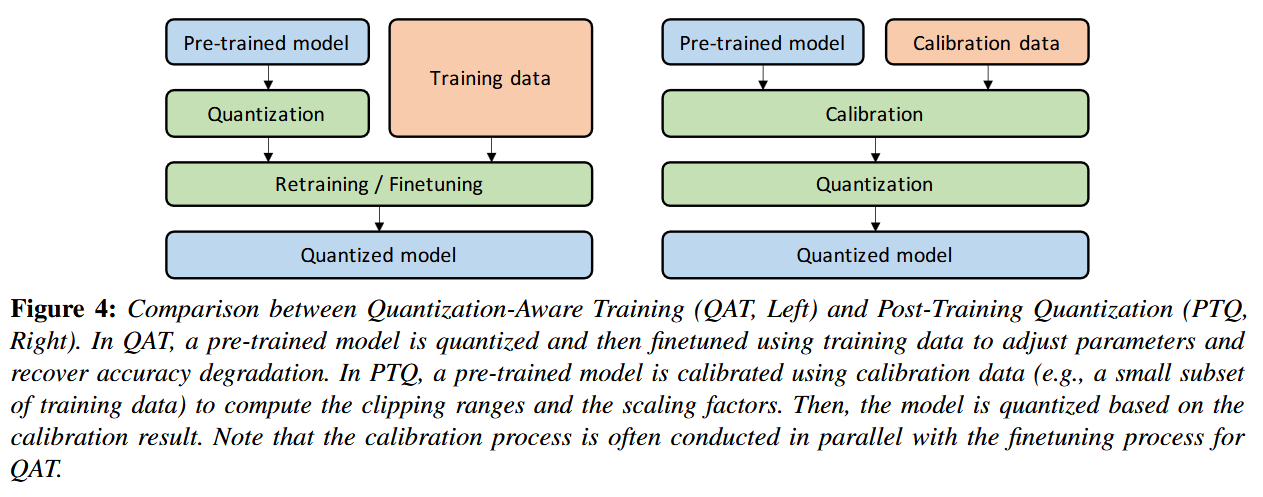

## Distillation

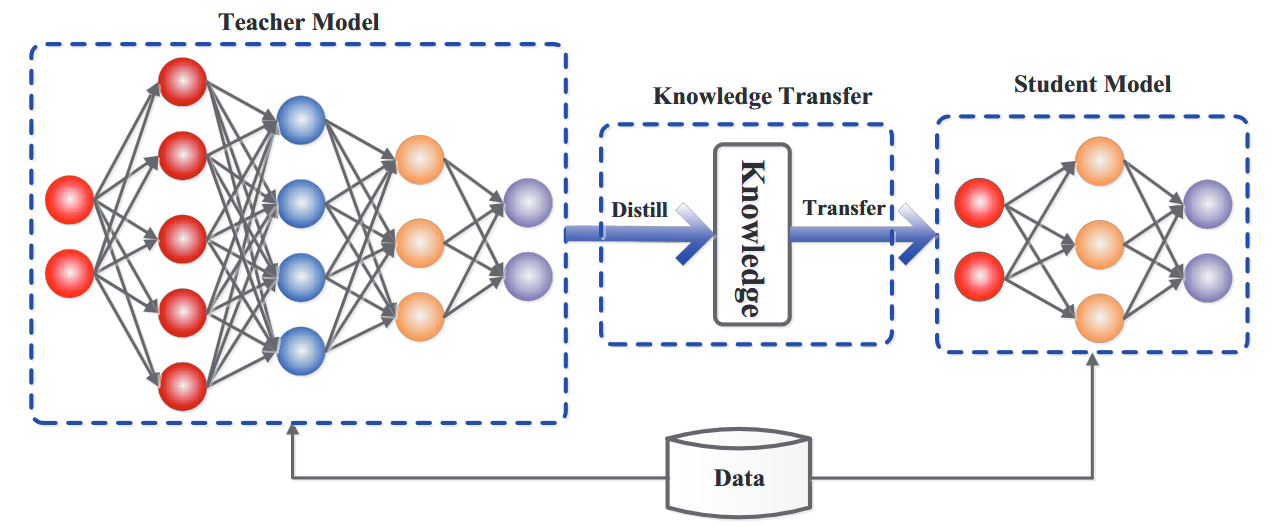

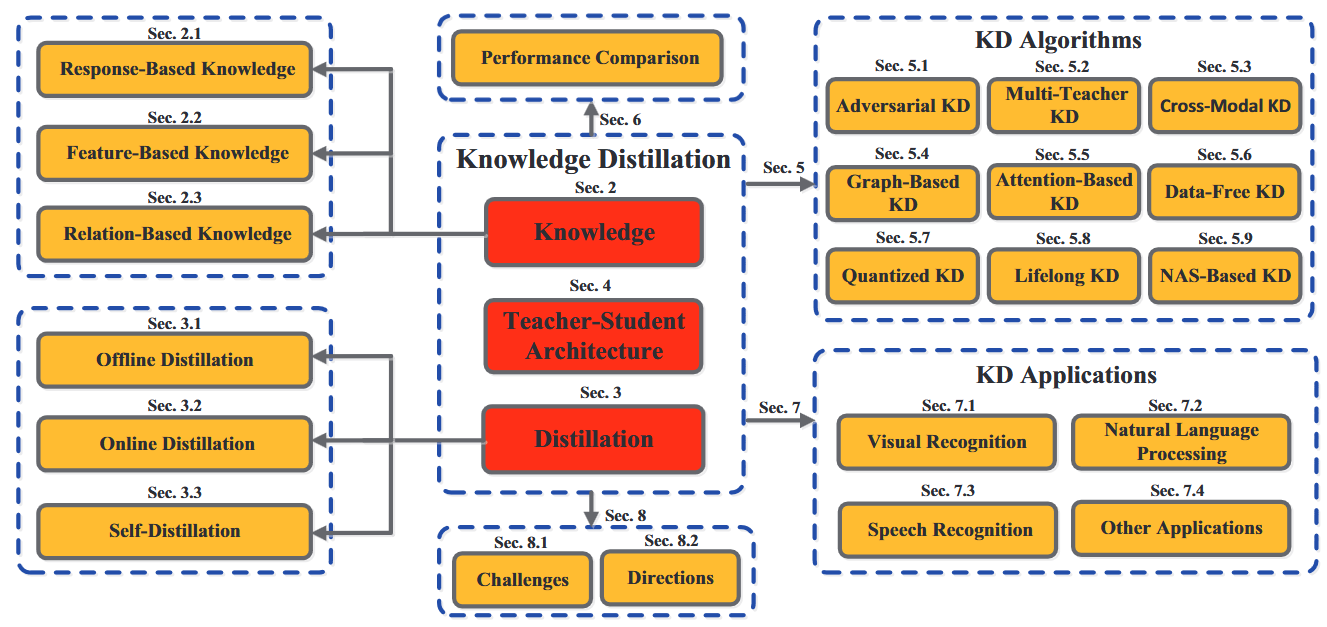

## GPTQ

Last year the [GPTQ: Accurate Post-Training Quantization for Generative Pre-trained Transformers](https://arxiv.org/abs/2210.17323) has been published by Frantar et al. The paper details an algorithm to compress any transformer-based language model in few bits with a tiny performance degradation.

We now support loading models that are quantized with GPTQ algorithm in 🤗 transformers thanks to the [`auto-gptq`](https://github.com/PanQiWei/AutoGPTQ.git) library that is used as backend.

Let's check in this notebook the different options (quantize a model, push a quantized model on the 🤗 Hub, load an already quantized model from the Hub, etc.) that are offered in this integration!

## Load required libraries

Let us first load the required libraries that are 🤗 transformers, optimum and auto-gptq library.

The GPTQ backend of `transformers` is `gptqmodel` (installed by the environment cell on a CUDA machine); `auto-gptq`, used when this notebook was written, is no longer maintained.

## Quantize transformers model using auto-gptq, 🤗 transformers and optimum

There are two different scenarios you might be interested in using this integration.

1- Quantize a language model from scratch.

2- Load a model that has been already quantized from 🤗 Hub


The GPTQ algorithm requires to calibrate the quantized weights of the model by doing inference on the quantized model. The detailed quantization algorithm is described in [the original paper](https://arxiv.org/pdf/2210.17323.pdf).

For quantizing a model using auto-gptq, we need to pass a dataset to the quantizer. This can be achieved either by passing a supported default dataset among `['wikitext2','c4','c4-new','ptb','ptb-new']` or a list of strings that will be used as a dataset.

### Quantize a model by passing a supported dataset




In the example below, let us try to quantize the model in 4-bit precision using the `"c4"` dataset. Supported precisions are `[2, 4, 6, 8]`.

Note that this cell will take more than 3 minutes to be completed. If you want to check how to quantize the model by passing a custom dataset, check out the next section.

In [3]:
from transformers import AutoModelForCausalLM, AutoTokenizer, GPTQConfig
import torch

model_id = "facebook/opt-125m"

quantization_config = GPTQConfig(
     bits=4,
     group_size=128,
     dataset="wikitext2",
     desc_act=False,
)

tokenizer = AutoTokenizer.from_pretrained(model_id)
quant_model = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=quantization_config, device_map='auto')

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/651 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

Quantizing layers inside the block:   0%|          | 0/6 [00:00<?, ?it/s]

Quantizing layers inside the block:   0%|          | 0/6 [00:00<?, ?it/s]

Quantizing layers inside the block:   0%|          | 0/6 [00:00<?, ?it/s]

Quantizing layers inside the block:   0%|          | 0/6 [00:00<?, ?it/s]

`loss_type=None` was set in the config but it is unrecognised.Using the default loss: `ForCausalLMLoss`.


You can make sure the model has been correctly quantized by checking the attributes of the linear layers, they should contain `qweight` and `qzeros` attributes that should be in `torch.int32` dtype.

In [4]:
quant_model.model.decoder.layers[0].self_attn.q_proj.__dict__

{'training': True,
 '_parameters': {},
 '_buffers': {'qweight': tensor([[ 1711760090, -1248295259, -2025411892,  ..., -1486452502,
            2019142072, -1735820810],
          [-2000132747,  -578262345,  1484081337,  ..., -1230600537,
           -2019252040, -2023311003],
          [ -710293851, -1153090188,  1431922298,  ..., -1768449094,
            2042194587, -2004125258],
          ...,
          [-1183500136, -1762945894, -1756001608,  ..., -1788237410,
            -394933383,  -679106902],
          [-1990626701,  1217620041,  1738299580,  ...,  1740212373,
           -2000991594, -1753806216],
          [-2010617241,  2023455605,  2005572185,  ..., -1211525767,
           -1450403976, -2024523140]], device='cuda:0', dtype=torch.int32),
  'qzeros': tensor([[2004318071, 2004318071, 2004318071, 2004318071, 2004318071, 2004318071,
           2004318071, 2004318071, 2004318071, 2004318071, 2004318071, 2004318071,
           2004318071, 2004318071, 2004318071, 2004318071, 20043180

Now let's perform an inference on the quantized model. Use the same API as transformers!

In [7]:
tokenizer = AutoTokenizer.from_pretrained(model_id)

text = "Hello my name is"
inputs = tokenizer(text, return_tensors="pt").to(0)

out = quant_model.generate(**inputs)
print(tokenizer.decode(out[0], skip_special_tokens=True))

Hello my name is Alex and I'm a 25 year old male. I'm a student at the University of California at


### Quantize a model by passing a custom dataset

You can also quantize a model by passing a custom dataset, for that you can provide a list of strings to the quantization config. A good number of sample to pass is 128. If you do not pass enough data, the performance of the model will suffer.

In [ ]:
from transformers import AutoModelForCausalLM, GPTQConfig, AutoTokenizer

model_id = "facebook/opt-125m"

quantization_config = GPTQConfig(
    bits=4,
    group_size=128,
    desc_act=False,
    dataset=["auto-gptq is an easy-to-use model quantization library with user-friendly apis, based on GPTQ algorithm."]
)

tokenizer = AutoTokenizer.from_pretrained(model_id)
quant_model = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=quantization_config, dtype=torch.float16, device_map="auto")

As you can see from the generation below, the performance seems to be slightly worse than the model quantized using the `c4` dataset.

In [9]:
text = "My name is"
inputs = tokenizer(text, return_tensors="pt").to(0)

out = quant_model.generate(**inputs)
print(tokenizer.decode(out[0], skip_special_tokens=True))

My name is "M""""""""""""""""""


## Load quantized models from the 🤗 Hub

You can load models that have been quantized using the auto-gptq library out of the box from the 🤗 Hub directly using `from_pretrained` method.

Make sure that the model on the Hub have an attribute `quantization_config` on the model config file, with the field `quant_method` set to `"gptq"` as you can see below.


<img src="https://huggingface.co/ybelkada/scratch-repo/resolve/main/images/gptq-example.png" width="300"/>

Most used quantized models can be found under [TheBloke](https://huggingface.co/TheBloke) namespace that contains most used models converted with auto-gptq library. The integration should work with most of these models out of the box (to confirm and test).

<img src="https://huggingface.co/ybelkada/scratch-repo/resolve/main/images/thebloke-example.png" width="800"/>


Below we will load a llama 7b quantized in 4bit.

In [10]:
from transformers import AutoTokenizer, AutoModelForCausalLM

model_id = "TheBloke/Llama-2-7b-Chat-GPTQ"
model = AutoModelForCausalLM.from_pretrained(model_id, device_map="auto")
tokenizer = AutoTokenizer.from_pretrained(model_id)

config.json:   0%|          | 0.00/789 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.90G [00:00<?, ?B/s]

Some weights of the model checkpoint at TheBloke/Llama-2-7b-Chat-GPTQ were not used when initializing LlamaForCausalLM: ['model.layers.0.mlp.down_proj.bias', 'model.layers.0.mlp.gate_proj.bias', 'model.layers.0.mlp.up_proj.bias', 'model.layers.0.self_attn.k_proj.bias', 'model.layers.0.self_attn.o_proj.bias', 'model.layers.0.self_attn.q_proj.bias', 'model.layers.0.self_attn.v_proj.bias', 'model.layers.1.mlp.down_proj.bias', 'model.layers.1.mlp.gate_proj.bias', 'model.layers.1.mlp.up_proj.bias', 'model.layers.1.self_attn.k_proj.bias', 'model.layers.1.self_attn.o_proj.bias', 'model.layers.1.self_attn.q_proj.bias', 'model.layers.1.self_attn.v_proj.bias', 'model.layers.10.mlp.down_proj.bias', 'model.layers.10.mlp.gate_proj.bias', 'model.layers.10.mlp.up_proj.bias', 'model.layers.10.self_attn.k_proj.bias', 'model.layers.10.self_attn.o_proj.bias', 'model.layers.10.self_attn.q_proj.bias', 'model.layers.10.self_attn.v_proj.bias', 'model.layers.11.mlp.down_proj.bias', 'model.layers.11.mlp.gate_p

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.llama.tokenization_llama_fast.LlamaTokenizerFast'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565 - if you loaded a llama tokenizer from a GGUF file you can ignore this message.


Once tokenizer and model has been loaded, let's generate some text. Before that, we can inspect the model to make sure it has loaded a quantized model

In [11]:
print(model)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(32000, 4096, padding_idx=0)
    (layers): ModuleList(
      (0-31): 32 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (k_proj): QuantLinear()
          (o_proj): QuantLinear()
          (q_proj): QuantLinear()
          (v_proj): QuantLinear()
        )
        (mlp): LlamaMLP(
          (act_fn): SiLU()
          (down_proj): QuantLinear()
          (gate_proj): QuantLinear()
          (up_proj): QuantLinear()
        )
        (input_layernorm): LlamaRMSNorm((4096,), eps=1e-06)
        (post_attention_layernorm): LlamaRMSNorm((4096,), eps=1e-06)
      )
    )
    (norm): LlamaRMSNorm((4096,), eps=1e-06)
    (rotary_emb): LlamaRotaryEmbedding()
  )
  (lm_head): Linear(in_features=4096, out_features=32000, bias=False)
)


As you can see, linear layers have been modified to `QuantLinear` modules from auto-gptq library.

Furthermore, we can see that from the quantization config that we are using exllama kernel (`disable_exllama = False`). Note that it only works with 4-bit model.

In [12]:
model.config.quantization_config.to_dict()

{'quant_method': <QuantizationMethod.GPTQ: 'gptq'>,
 'bits': 4,
 'tokenizer': None,
 'dataset': None,
 'group_size': 128,
 'damp_percent': 0.01,
 'desc_act': False,
 'sym': True,
 'true_sequential': True,
 'checkpoint_format': 'gptq',
 'meta': None,
 'backend': None,
 'use_cuda_fp16': False,
 'model_seqlen': None,
 'block_name_to_quantize': None,
 'module_name_preceding_first_block': None,
 'batch_size': 1,
 'pad_token_id': None,
 'use_exllama': True,
 'max_input_length': None,
 'exllama_config': {'version': <ExllamaVersion.ONE: 1>},
 'cache_block_outputs': True,
 'modules_in_block_to_quantize': None}

In [13]:
text = "Hello my name is"
inputs = tokenizer(text, return_tensors="pt").to(0)

out = model.generate(**inputs, max_new_tokens=50)
print(tokenizer.decode(out[0], skip_special_tokens=True))

/usr/local/lib/python3.11/dist-packages/transformers/generation/utils.py:1667: UserWarning: You have modified the pretrained model configuration to control generation. This is a deprecated strategy to control generation and will be removed in v5. Please use and modify the model generation configuration (see https://huggingface.co/docs/transformers/generation_strategies#default-text-generation-configuration )
  warnings.warn(


Hello my name is Sarah and I am a 3rd year PhD student in the Department of Computer Science at the University of Cambridge. My research focuses on developing machine learning algorithms for medical image analysis, with a particular interest in brain imaging. I am super


## Train quantized model using 🤗 PEFT

Let's train the `llama-2` model using PEFT library from Hugging Face 🤗. We disable the exllama kernel because training with exllama kernel is unstable. To do that, we pass a `GPTQConfig` object with `use_exllama=False`. This will overwrite the value stored in the config of the model.

In [ ]:
from peft import prepare_model_for_kbit_training

model_id = "TheBloke/Llama-2-7b-Chat-GPTQ"
quantization_config_loading = GPTQConfig(bits=4, use_exllama=False)
model = AutoModelForCausalLM.from_pretrained(model_id,quantization_config=quantization_config_loading, device_map="auto")

In [15]:
model.config.quantization_config.to_dict()

{'quant_method': <QuantizationMethod.GPTQ: 'gptq'>,
 'bits': 4,
 'tokenizer': None,
 'dataset': None,
 'group_size': 128,
 'damp_percent': 0.01,
 'desc_act': False,
 'sym': True,
 'true_sequential': True,
 'checkpoint_format': 'gptq',
 'meta': None,
 'backend': None,
 'use_cuda_fp16': False,
 'model_seqlen': None,
 'block_name_to_quantize': None,
 'module_name_preceding_first_block': None,
 'batch_size': 1,
 'pad_token_id': None,
 'use_exllama': True,
 'max_input_length': None,
 'exllama_config': {'version': <ExllamaVersion.ONE: 1>},
 'cache_block_outputs': True,
 'modules_in_block_to_quantize': None}

First, we have to apply some preprocessing to the model to prepare it for training. For that, use the `prepare_model_for_kbit_training` method from PEFT.

In [16]:
model.gradient_checkpointing_enable()
model = prepare_model_for_kbit_training(model)

Then, we need to convert the model into a peft model using get_peft_model.

In [17]:
from peft import LoraConfig, get_peft_model
config = LoraConfig(
    r=8,
    lora_alpha=32,
    target_modules=["k_proj","o_proj","q_proj","v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

model = get_peft_model(model, config)
model.print_trainable_parameters()

trainable params: 8,388,608 || all params: 270,798,848 || trainable%: 3.0977


Finally, let's load a dataset and we can train our model.

In [18]:
from datasets import load_dataset

data = load_dataset("Abirate/english_quotes")
data = data.map(lambda samples: tokenizer(samples["quote"]), batched=True)

Extracting data files:   0%|          | 0/1 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/2508 [00:00<?, ? examples/s]

In [21]:
from transformers import Trainer, TrainingArguments, DataCollatorForLanguageModeling

# needed for llama 2 tokenizer
tokenizer.pad_token = tokenizer.eos_token

trainer = Trainer(
    model=model,
    train_dataset=data["train"],
    args=TrainingArguments(
        per_device_train_batch_size=1,
        gradient_accumulation_steps=4,
        warmup_steps=2,
        max_steps=10,
        learning_rate=2e-4,
        fp16=True,
        logging_steps=1,
        output_dir="outputs",
        optim="adamw_torch",
        report_to="none",
    ),
    data_collator=DataCollatorForLanguageModeling(tokenizer, mlm=False)
)
model.config.use_cache = False  # silence the warnings. Please re-enable for inference!
trainer.train()

No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.
/usr/local/lib/python3.11/dist-packages/torch/_dynamo/eval_frame.py:745: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss
1,2.551900
2,2.030800
3,2.371100
4,1.856500
5,2.040000
6,1.542300
7,2.242700
8,1.304300
9,2.472100
10,2.139500


TrainOutput(global_step=10, training_loss=2.0551214098930357, metrics={'train_runtime': 69.7229, 'train_samples_per_second': 0.574, 'train_steps_per_second': 0.143, 'total_flos': 1275147214848.0, 'train_loss': 2.0551214098930357, 'epoch': 0.01594896331738437})

In [23]:
model.config.use_cache = True

In [24]:
text = "An apple per day"
inputs = tokenizer(text, return_tensors="pt").to(0)

out = model.generate(**inputs, max_new_tokens=50)
print(tokenizer.decode(out[0], skip_special_tokens=True))

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


An apple per day keeps the doctor away, but what about the other fruits and vegetables?

Fruits and vegetables are an important part of a healthy diet, providing essential nutrients, fiber, and other beneficial compounds.


## Exploring further

AutoGPTQ library offers multiple advanced options for users that wants to explore features such as fused attention or triton backend.

Therefore, we kindly advise users to explore [AutoGPTQ](https://github.com/PanQiWei/AutoGPTQ) library for more details.